# Road to Safety — Chronological baseline severity models

## tl;dr

This phase freezes and evaluates a training-prevalence baseline and a single interpretable L2 logistic regression using the eight approved categorical condition features. The target is fatal versus nonfatal injury **conditional on a recorded fatal/injury collision**, not accident occurrence.

- Training: **1999–2016**, 2,455,890 collisions, 39,491 fatal.
- Validation: **2017–2019**, 330,376 collisions, 5,072 fatal.
- Retrospective temporal test: **2020–2021**, 163,580 collisions, 3,230 fatal.

Test logistic log loss is **0.092626**, versus **0.097444** for prevalence; Brier is **0.019177** versus **0.019369**. ROC-AUC is **0.6992** and average precision **4.208%**. At the illustrative threshold, recall is **82.11%** with precision **2.92%**. Mean prediction **1.6036%** is below observed **1.9746%**; improvement is modest and calibration shifts in the test years. See [full model findings](../docs/severity_modeling.md), [protocol](../docs/severity_protocol.md), [model card](../models/severity_model_card.md), and [independent validation](../docs/severity_validation.md).

The newest years were already examined descriptively in EDA: this is not wholly unseen prospective evaluation. No model or threshold is changed after inspecting test performance.

## Context & Methods

### Key Assumptions

Use the selected NCDB 1999–2021 collision releases and the binary `is_fatal` target. One candidate collision contributes once. Unknown/other/unavailable source categories remain distinct. There is no complete-case exclusion, class balancing, random split or exposure denominator.

The eight categorical predictors are month, weekday, hour, road configuration, weather, surface, alignment and traffic control. Dictionary domains and reference levels are frozen external metadata, with supported training-unobserved levels flagged as unsupported evidence. No year, identifier, casualty outcome or diagnostic enters the estimator. Reported conditions are post-crash observations; prospective availability remains unverified.

One-hot encoding drops declared reference levels. A single L2 logistic regression uses C=1, lbfgs, max_iter=1000, tolerance1e-7 and seed2026. Baseline probability is the training fatal proportion. Coefficients and prevalence use training only; validation selects only an illustrative threshold attaining at least80% recall and maximizing precision, with ties choosing the higher threshold. There is no calibration fit, hyperparameter search or training+validation refit.

Evaluate natural-log log loss, Brier score, average precision and ROC-AUC; threshold precision/recall/F1 and confusion counts at0.5 and the validation-selected threshold; fixed10-bin calibration diagnostics and ECE. Sparse groups have n<100 or fatal<5 and remain in results. These are descriptive model assessments, not inferential confidence intervals or deployment acceptance.

### Reproduction

Run from the project root:

```bash
uv sync --locked --python 3.13 --extra notebook
OPENBLAS_NUM_THREADS=2 OMP_NUM_THREADS=2 MPLCONFIGDIR=/tmp/road-to-safety-mpl .venv/bin/python -m road_to_safety.fit_severity
.venv/bin/python -m road_to_safety.validate_severity
```

This notebook reads the exact saved run and independently validates it; it does not refit a model merely to display results. Rerun the fitting command explicitly to regenerate the complete pinned run. Source modules contain the editable fitting and plotting logic.

## Data

### Verify the saved run and frozen inputs

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
protocol=json.loads((ROOT/'data/reference/severity_protocol.json').read_text())
print('Frozen at:',protocol['frozen_at_utc'])
print('Model:',protocol['logistic_regression'])

def table(name): return pd.read_csv(ROOT/'reports/tables'/name)
def figure(name): display(Image(filename=str(ROOT/'reports/figures'/name),width=1000))


Frozen at: 2026-10-18T15:58:29.482123+00:00
Model: {'penalty': 'l2', 'C': 1.0, 'solver': 'lbfgs', 'max_iter': 1000, 'tol': 1e-07, 'random_state': 2026, 'fit_intercept': True, 'class_weight': None, 'sample_weight': None, 'resampling': False, 'hyperparameter_search': False, 'calibration_fit': False}


### Independent validation

The validator checks source and protocol fingerprints, split conservation, probability reconstruction from coefficients, baseline/threshold calculations, metrics and subgroup denominators without refitting.

In [2]:
from road_to_safety.validate_severity import validate
validation=validate(ROOT)
assert validation['status']=='passed',validation
print('Independent validation:',validation['status'])

Independent validation: passed


## Results

### Split and annual performance

Probability scores are the primary baseline comparison. Lower log loss/Brier is better; higher average precision/ROC-AUC is better. Precision–recall interpretation must retain the period prevalence.

In [3]:
metrics=table('severity_metrics.csv')
probability_columns=['group','model','n','fatal','fatal_proportion','mean_prediction','log_loss','brier_score','average_precision','roc_auc','ece']
display(metrics[metrics.group_kind.eq('split') & metrics.threshold_kind.eq('fixed_0_5')][probability_columns])
display(metrics[metrics.group_kind.eq('year') & metrics['group'].astype(str).isin(['2019','2020','2021']) & metrics.threshold_kind.eq('fixed_0_5')][probability_columns])

,group,model,n,fatal,fatal_proportion,mean_prediction,log_loss,brier_score,average_precision,roc_auc,ece
0,train,prevalence,2455890,39491,0.016080,0.016080,0.082364,0.015822,0.016080,0.500000,0.000000
2,train,logistic,2455890,39491,0.016080,0.016080,0.077959,0.015662,0.037968,0.706848,0.000036
4,validation,prevalence,330376,5072,0.015352,0.016080,0.079369,0.015117,0.015352,0.500000,0.000728
6,validation,logistic,330376,5072,0.015352,0.015560,0.075583,0.014991,0.034163,0.696042,0.000207
8,test,prevalence,163580,3230,0.019746,0.016080,0.097444,0.019369,0.019746,0.500000,0.003666
10,test,logistic,163580,3230,0.019746,0.016036,0.092626,0.019177,0.042081,0.699171,0.003788


,group,model,n,fatal,fatal_proportion,mean_prediction,log_loss,brier_score,average_precision,roc_auc,ece
92,2019,prevalence,104630,1620,0.015483,0.016080,0.079908,0.015244,0.015483,0.500000,0.000597
94,2019,logistic,104630,1620,0.015483,0.015460,0.076075,0.015118,0.034066,0.697768,0.000080
96,2020,prevalence,79990,1602,0.020028,0.016080,0.098603,0.019642,0.020028,0.500000,0.003947
98,2020,logistic,79990,1602,0.020028,0.016068,0.093622,0.019439,0.043246,0.700600,0.004022
100,2021,prevalence,83590,1628,0.019476,0.016080,0.096334,0.019108,0.019476,0.500000,0.003396
102,2021,logistic,83590,1628,0.019476,0.016006,0.091673,0.018926,0.041108,0.697752,0.003565


### Illustrative classification thresholds

The same validation-selected numerical threshold applies to both models; no threshold is selected on test labels. This operating point prioritizes validation recall and does not establish an intervention budget.

In [4]:
display(metrics[metrics.group_kind.eq('split') & metrics['group'].isin(['validation','test'])][['group','model','threshold_kind','threshold','n','tp','fp','fn','tn','precision','recall','f1']])

,group,model,threshold_kind,threshold,n,tp,fp,fn,tn,precision,recall,f1
4,validation,prevalence,fixed_0_5,0.500000,330376,0,0,5072,325304,0.000000,0.000000,0.000000
5,validation,prevalence,validation_recall_80,0.011512,330376,5072,325304,0,0,0.015352,1.000000,0.030240
6,validation,logistic,fixed_0_5,0.500000,330376,0,0,5072,325304,0.000000,0.000000,0.000000
7,validation,logistic,validation_recall_80,0.011512,330376,4058,174732,1014,150572,0.022697,0.800079,0.044142
8,test,prevalence,fixed_0_5,0.500000,163580,0,0,3230,160350,0.000000,0.000000,0.000000
9,test,prevalence,validation_recall_80,0.011512,163580,3230,160350,0,0,0.019746,1.000000,0.038727
10,test,logistic,fixed_0_5,0.500000,163580,0,0,3230,160350,0.000000,0.000000,0.000000
11,test,logistic,validation_recall_80,0.011512,163580,2652,88276,578,72074,0.029166,0.821053,0.056331


### Model figures

Calibration is assessed on the saved raw probabilities; no post-test correction is fitted. Annual diagnostics distinguish the 2020 and2021 case mix from development years.

#### Annual Performance

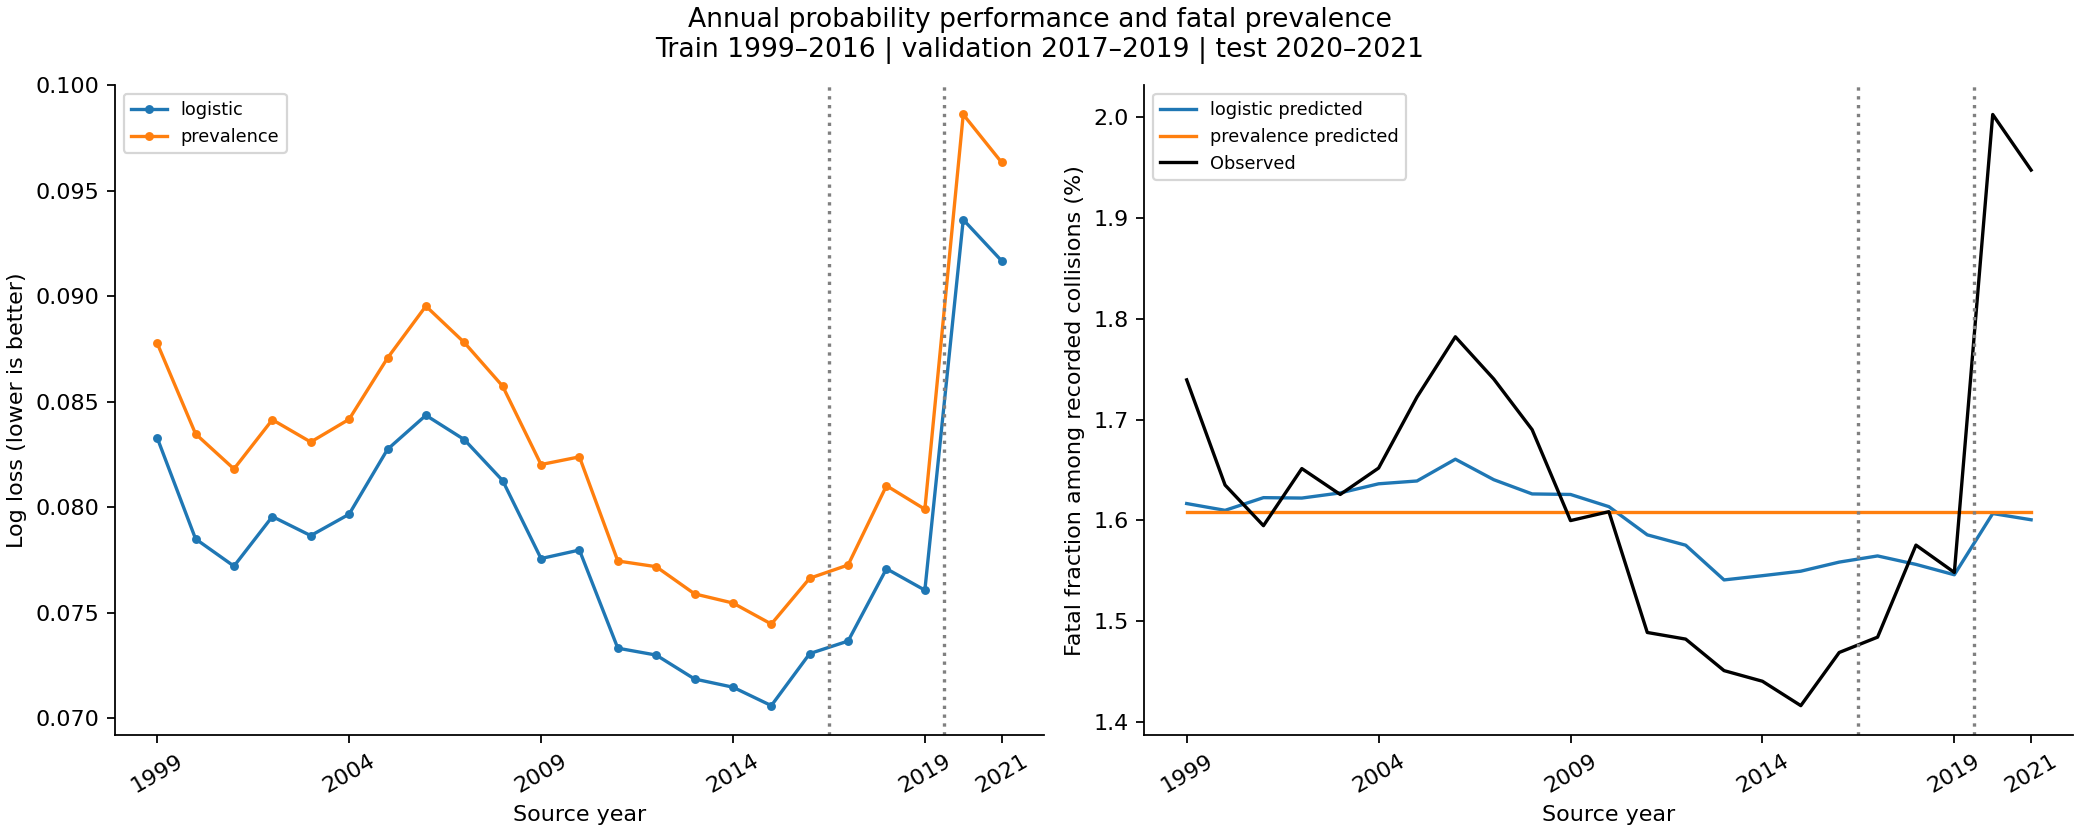

In [5]:
figure('severity_annual_performance.png')

#### Calibration

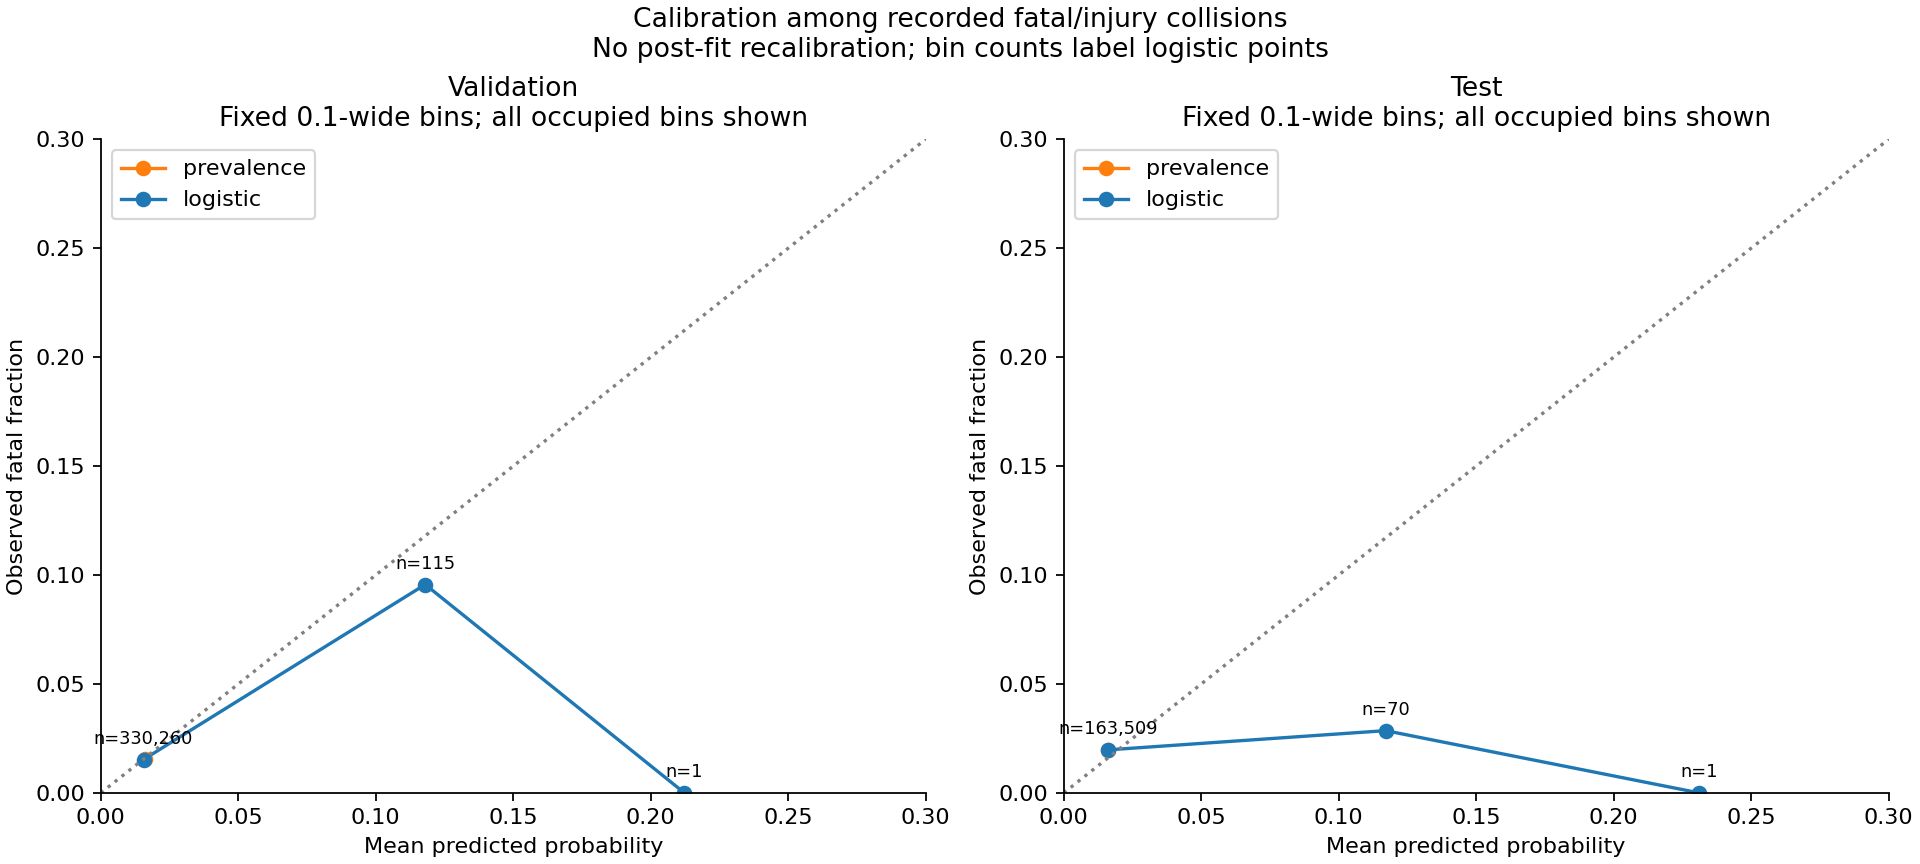

In [6]:
figure('severity_calibration.png')

#### Coefficients

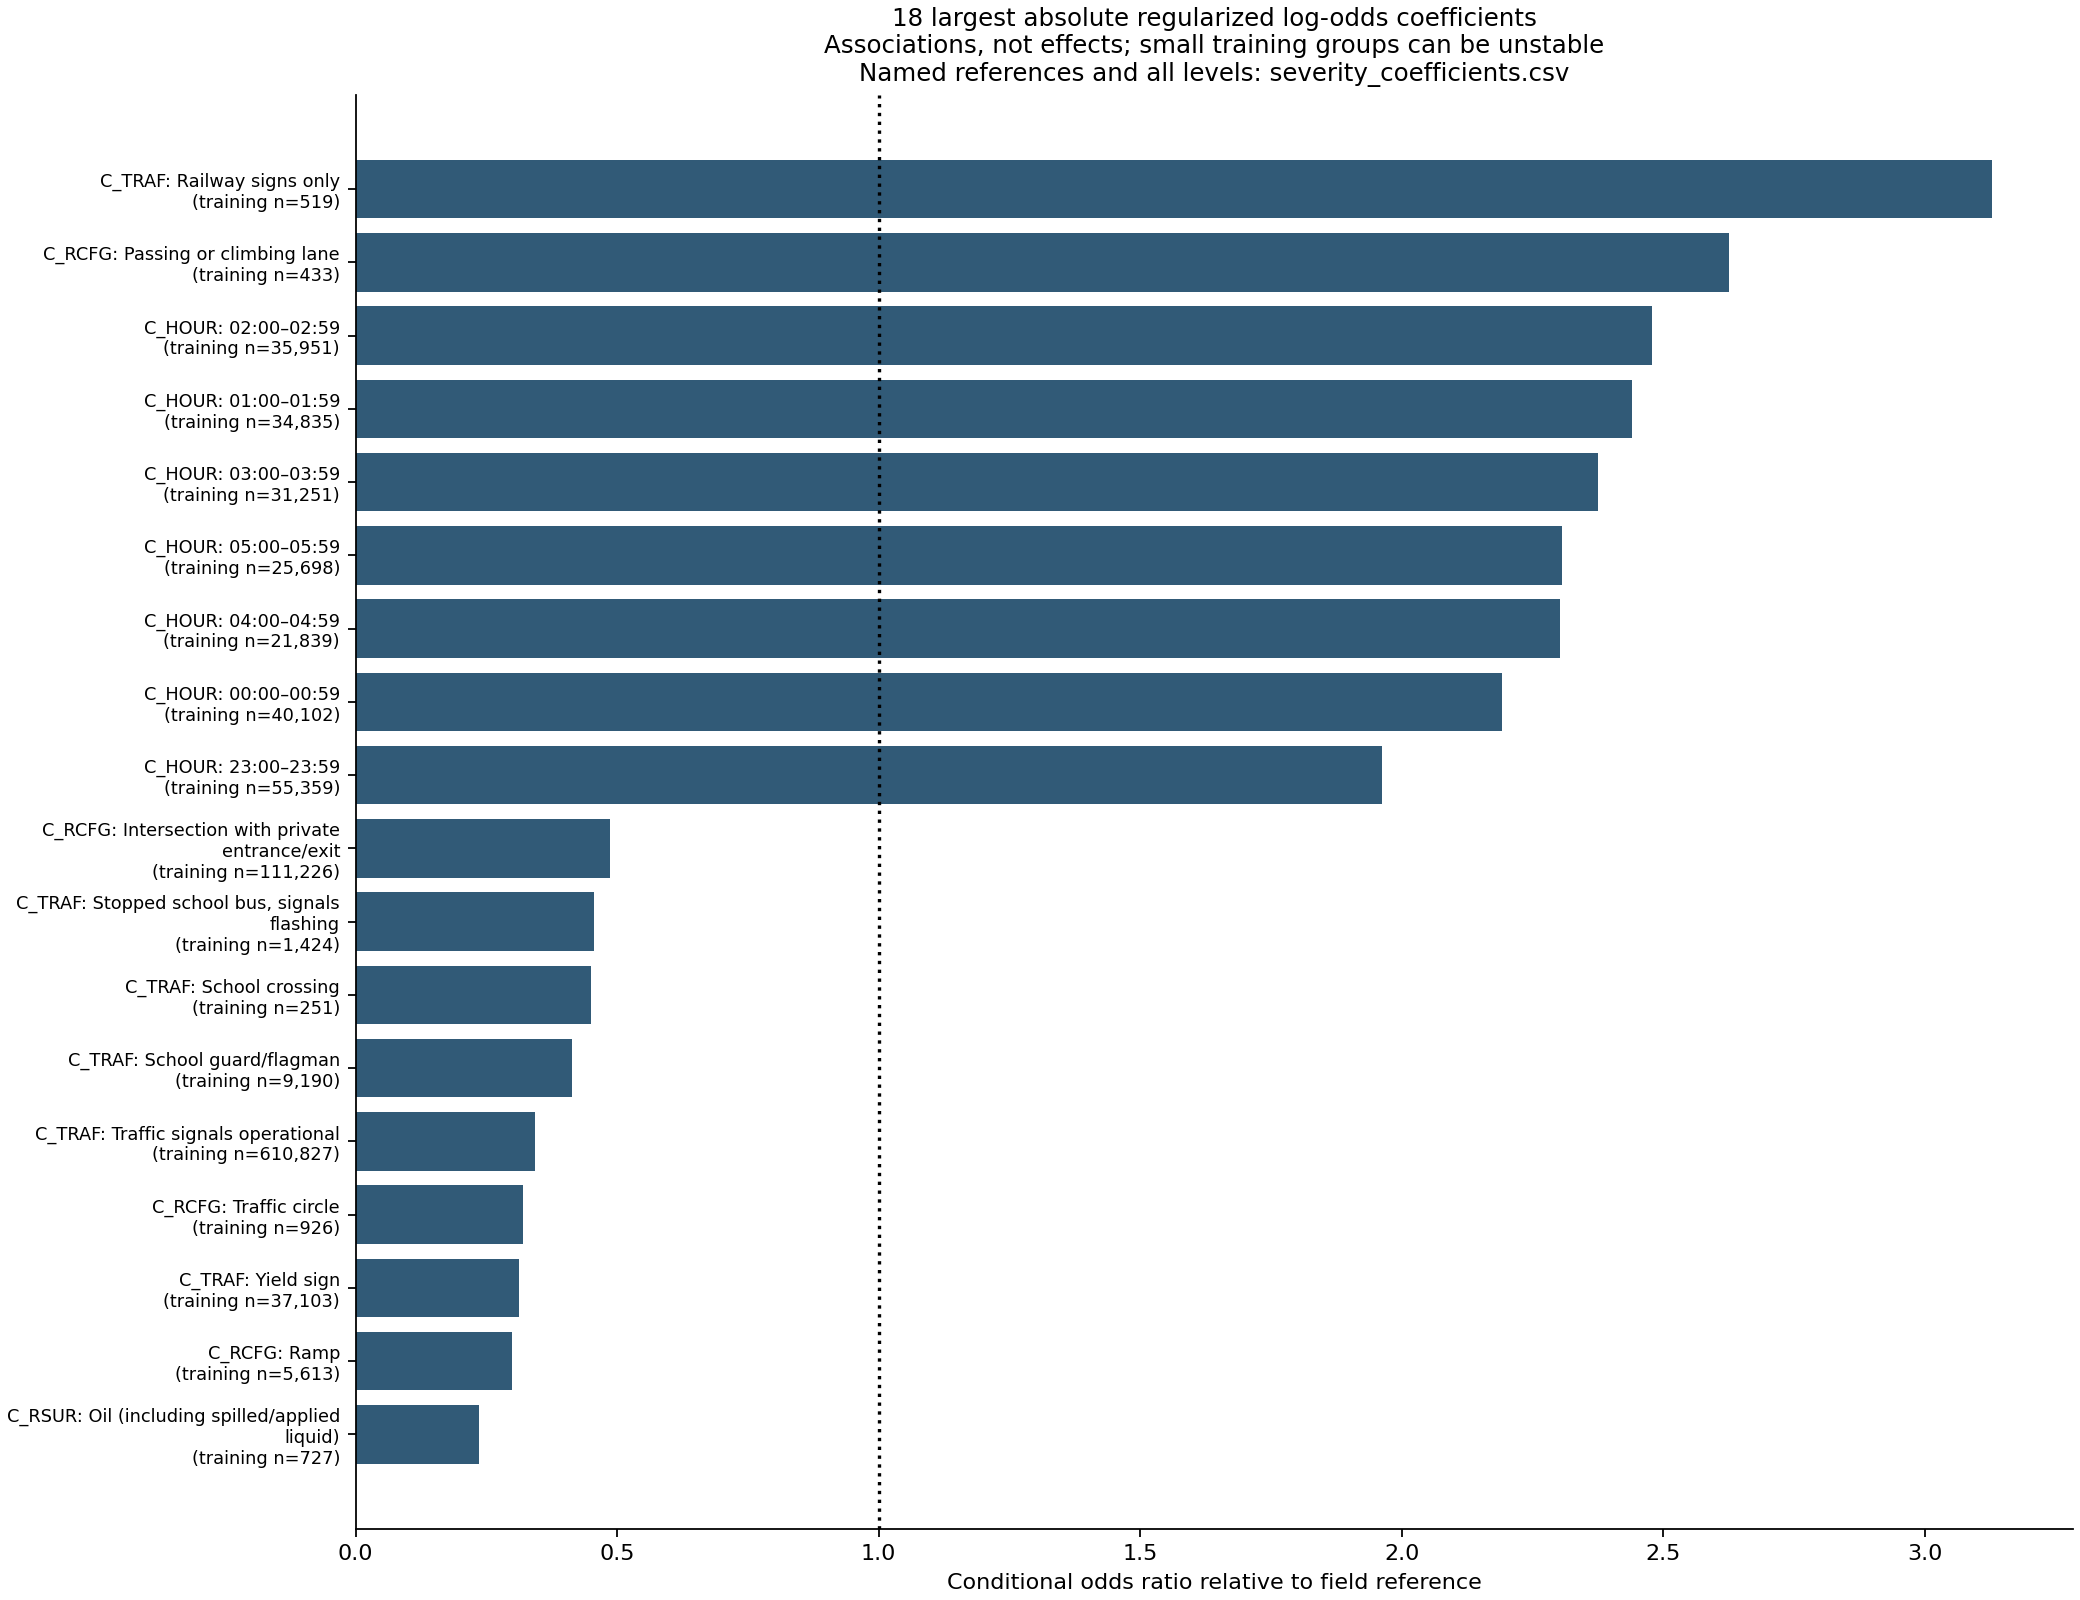

In [7]:
figure('severity_coefficients.png')

#### Precision Recall

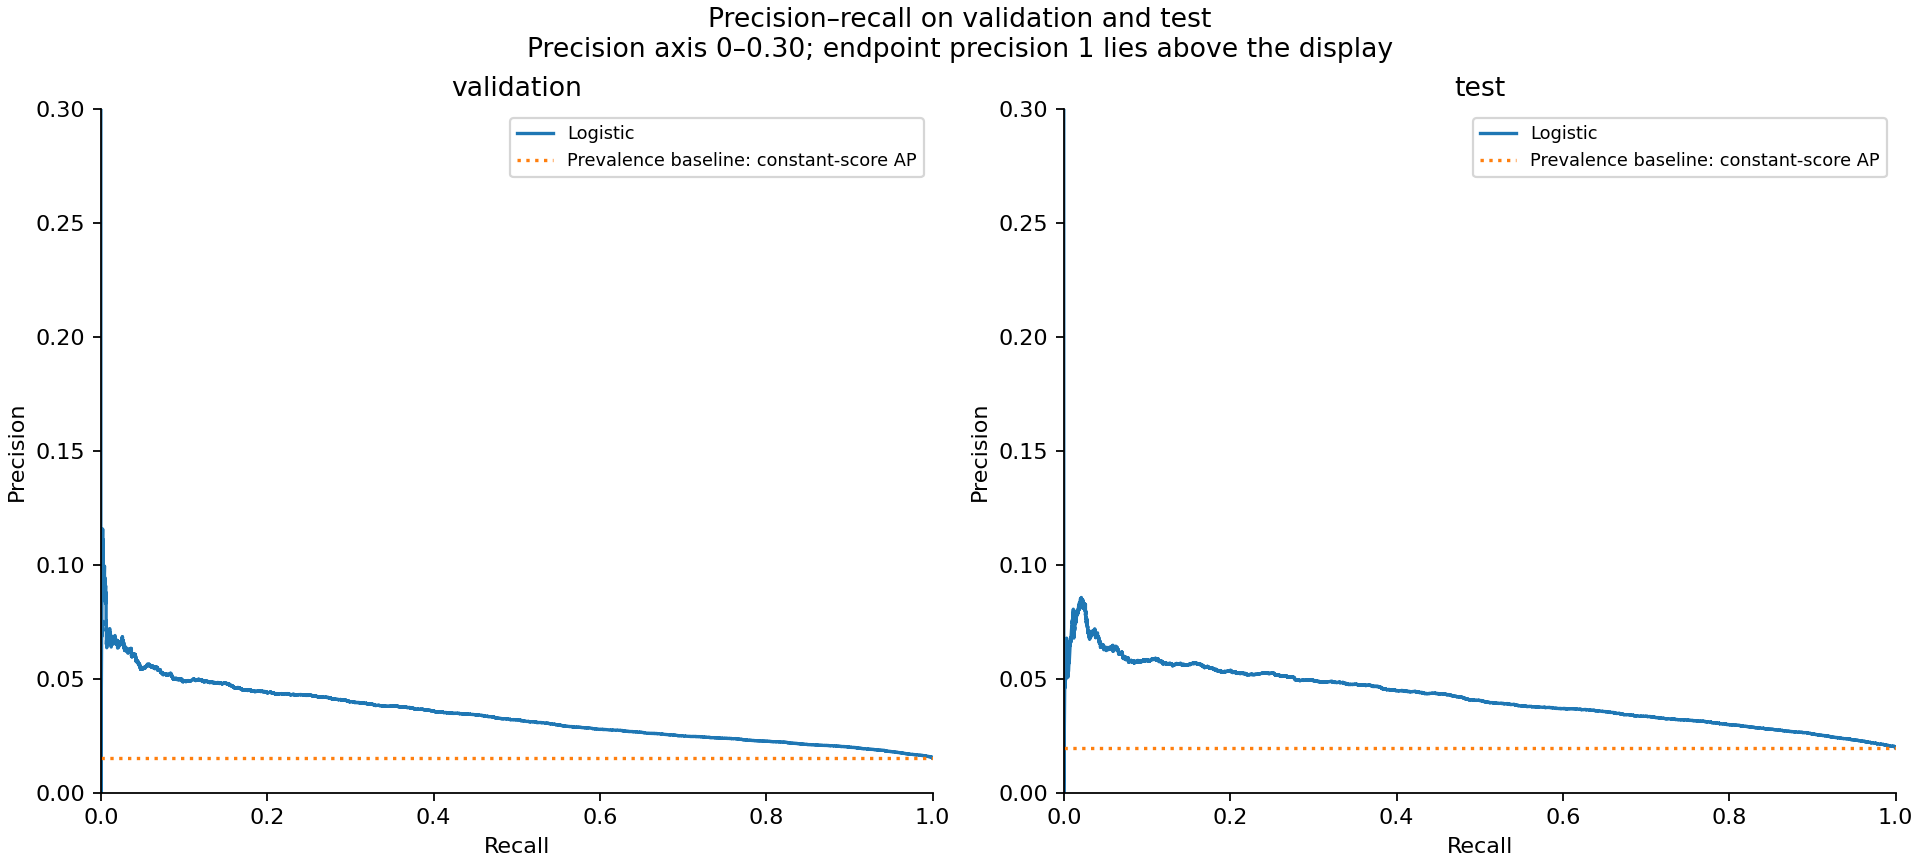

In [8]:
figure('severity_precision_recall.png')

In [9]:
calibration=table('severity_calibration.csv')
display(calibration[calibration.group_kind.eq('split') & calibration['group'].isin(['validation','test']) & calibration.n.gt(0)][['group','model','bin','n','fatal','mean_prediction','observed_fraction']])

,group,model,bin,n,fatal,mean_prediction,observed_fraction
20,validation,prevalence,0,330376,5072,0.016080,0.015352
30,validation,logistic,0,330260,5061,0.015523,0.015324
31,validation,logistic,1,115,11,0.117983,0.095652
32,validation,logistic,2,1,0,0.212264,0.000000
40,test,prevalence,0,163580,3230,0.016080,0.019746
50,test,logistic,0,163509,3228,0.015992,0.019742
51,test,logistic,1,70,2,0.117057,0.028571
52,test,logistic,2,1,0,0.231094,0.000000


### Coefficients and support

Exponentiated coefficients are regularized conditional odds ratios relative to the fixed reference level while holding the other encoded terms constant. They do not establish causal effects. Rare and training-unobserved levels need the explicit support flags; no significance or confidence-interval claims are made.

In [10]:
coefficient_path=ROOT/'reports/tables/severity_coefficients.csv'
coefficients=pd.read_csv(coefficient_path)
display(coefficients.head(30))
print('Complete coefficient table:',coefficient_path.relative_to(ROOT))

,feature,code,label,reference_code,reference_label,is_reference,train_count,train_unobserved,coefficient,odds_ratio,interpretation
0,C_MNTH,1,January,1,January,True,211820,False,0.000000,1.000000,reference
1,C_MNTH,2,February,1,January,False,178784,False,-0.037251,0.963434,conditional association; regularized
2,C_MNTH,3,March,1,January,False,173399,False,-0.037061,0.963617,conditional association; regularized
3,C_MNTH,4,April,1,January,False,164720,False,0.032441,1.032973,conditional association; regularized
4,C_MNTH,5,May,1,January,False,196280,False,0.039703,1.040501,conditional association; regularized
5,C_MNTH,6,June,1,January,False,217738,False,0.027583,1.027966,conditional association; regularized
6,C_MNTH,7,July,1,January,False,220996,False,0.113776,1.120501,conditional association; regularized
7,C_MNTH,8,August,1,January,False,223244,False,0.124518,1.132602,conditional association; regularized
8,C_MNTH,9,September,1,January,False,215622,False,0.120285,1.127819,conditional association; regularized
9,C_MNTH,10,October,1,January,False,217336,False,0.112660,1.119251,conditional association; regularized


Complete coefficient table: reports/tables/severity_coefficients.csv


### Late-period and sparse-group checks

Detailed tables retain year/feature/category denominators and sparse warnings, allowing inspection of unknown/other categories and the2020–2021 population. Groups are overlapping feature summaries and must not be added as counts of unique collisions.

In [11]:
display(metrics[metrics.group_kind.eq('split_feature_status') & metrics['group'].str.startswith('test:') & metrics.model.eq('logistic') & metrics.threshold_kind.eq('validation_recall_80')][['group','n','fatal','fatal_proportion','mean_prediction','precision','recall']])
distributions=table('severity_feature_distributions.csv')
unknown=distributions[distributions.group_kind.eq('split') & distributions.value_class.eq('unknown')]
display(unknown.pivot(index='feature',columns='group',values='share').mul(100).rename_axis('Unknown share (%) by feature'))

,group,n,fatal,fatal_proportion,mean_prediction,precision,recall
131,test:complete_stated,129440,2536,0.019592,0.016050,0.028911,0.813486
135,test:contains_unknown_or_unavailable,24303,459,0.018887,0.014367,0.030529,0.793028
139,test:contains_other,9837,235,0.023889,0.019973,0.029416,0.957447


group,test,train,validation
Unknown share (%) by feature,,,
C_HOUR,1.021519,1.097688,0.796668
C_MNTH,0.001834,0.004275,0.001211
C_RALN,5.124098,6.862197,4.826016
C_RCFG,5.607042,8.429694,5.528549
C_RSUR,1.067368,1.328928,0.980701
C_TRAF,5.940824,4.371043,5.371153
C_WDAY,0.001834,0.021133,0.001211
C_WTHR,1.588825,1.559638,1.364203


In [12]:
print('Available evidence tables:')
for path in sorted((ROOT/'reports/tables').glob('severity_*.csv')):
    print(path.name, len(pd.read_csv(path)), 'rows')

Available evidence tables:
severity_calibration.csv 7000 rows
severity_coefficients.csv 116 rows
severity_feature_distributions.csv 3016 rows
severity_metrics.csv 1400 rows
severity_training_levels.csv 116 rows
severity_validation_checks.csv 22 rows


## Takeaways

Read the model findings and model card for exact measured improvements, calibration limitations, illustrative threshold tradeoffs and year-specific stability. A ranking gain alone does not establish operational usefulness. The0.5 threshold is a conventional diagnostic and may detect few rare fatal outcomes; the validation-selected80% recall point has no assumed intervention budget or cost optimum.

This run completes a fixed baseline evaluation. A future modeling iteration should be separately specified and compared without repeatedly treating the same test years as untouched. Additional prospective evidence, exposure/non-crash observations and geographic data remain outside this dataset.

The notebook executes top-to-bottom and saves outputs. Standalone model charts are visually inspected separately; a rendered whole-notebook page preview remains unverified because of the previously recorded local browser URL-policy restriction.